# Medicaid prescription spending

**Mohammed Mia | Python + SQL | 2024**

I built this analysis to answer a practical question: **where does Medicaid prescription spending concentrate, and which products deserve a closer price review?**

I work through the data, prepare a product-enriched utilization table, and use SQL to answer three questions: which product NDCs account for spending, how spending varies across jurisdictions and quarters, and where comparable products have different reimbursement per unit.

The dataset covers **11 states and Washington, DC**. It contains **$27.54B in reported reimbursement before rebates**. This is a descriptive analysis of the included extract; it is not a national spending estimate.

In [1]:
from pathlib import Path
import sys
import json
import sqlite3
import pandas as pd

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/medicaid_analytics").exists())
sys.path.insert(0, str(ROOT / "src"))
from medicaid_analytics.pipeline import run
from medicaid_analytics.prepare import prepare_utilization, prepare_directory, attach_metadata
from medicaid_analytics.compare import reimbursement_gaps
from medicaid_analytics.verify import verify

if not (ROOT / "data/processed/analytics.sqlite").exists():
    run(ROOT)
summary = json.loads((ROOT / "reports/analysis_summary.json").read_text())
connection = sqlite3.connect(ROOT / "data/processed/analytics.sqlite")
print(summary["scope"])


2024 Medicaid utilization extract: 11 states and Washington, DC


## 1. Get to know the data

I start with utilization records and a product directory. A utilization record represents a reporting type, jurisdiction, package NDC, year, and quarter. The product directory supplies the ingredient, formulation, and application category.

I load NDCs as text because their leading zeros matter. I use only the source fields needed for this analysis.

In [2]:
columns = ["source_row", "Utilization Type", "State", "NDC", "Year", "Quarter",
           "Suppression Used", "Product Name", "Units Reimbursed",
           "Number of Prescriptions", "Medicaid Amount Reimbursed"]
records = pd.read_csv(ROOT / "data/raw/utilization.csv.gz", usecols=columns, dtype={"NDC": "string"})
product_records = pd.read_csv(ROOT / "data/raw/product_directory.csv.gz", dtype="string")
print(f"Utilization records: {len(records):,}")
print(f"Product listings: {len(product_records):,}")
print(records[["State", "NDC", "Quarter", "Suppression Used"]].head().to_string(index=False))


Utilization records: 1,048,575
Product listings: 113,878
State         NDC  Quarter  Suppression Used
   HI 00002015204        4                 1
   AK 00002021301        1                 1
   AL 00002021301        4                 0
   AL 00002021301        3                 0
   AL 00002021301        2                 0


## 2. Keep missing amounts separate from zero

**Question:** which records can support spending and price calculations?

I check reporting fields, NDC format, suppression, duplicates, and numeric values. Suppressed amounts remain missing. A price calculation additionally requires positive units. The preparation function keeps these rules in one place so the notebook and pipeline use the same definitions.

In [3]:
utilization, record_stats = prepare_utilization(records)
print(f"Records with reported reimbursement: {record_stats['spend_eligible_records']:,}")
print(f"Records with suppressed amounts: {record_stats['suppressed_records']:,}")
print(f"Reported reimbursement: ${record_stats['observed_pre_rebate_reimbursement']:,.2f}")
print("Jurisdictions:", ", ".join(record_stats["observed_states"]))


Records with reported reimbursement: 504,630
Records with suppressed amounts: 543,945
Reported reimbursement: $27,539,974,390.90
Jurisdictions: AK, AL, AR, AZ, CA, CO, CT, DC, DE, FL, GA, HI


**Observation:** 504,630 records contain reported reimbursement, while 543,945 have suppressed amounts. **Decision:** I use reported amounts for spending totals and retain all observations for coverage reporting. I do not estimate the dollars hidden by suppression.

## 3. Join product information without changing spending

**Question:** can each utilization record receive one product description?

I normalize the directory's segmented product codes and join them to the product portion of the package NDC. I collapse identical descriptors, leave conflicting keys unmatched, and require a many-to-one left join. This keeps unmatched spending in the denominator and prevents duplicate listings from multiplying reimbursement.

In [4]:
directory, conflicts, directory_stats = prepare_directory(product_records)
joined, join_stats = attach_metadata(utilization, directory)
print(f"Conflicting product keys left unmatched: {directory_stats['conflicting_directory_keys']:,}")
print(f"Product metadata coverage by dollars: {join_stats['matched_spending_share']:.2%}")
print(f"Unmatched reimbursement retained in totals: ${join_stats['unmatched_reimbursement']:,.2f}")
print(f"Utilization rows before / after join: {len(utilization):,} / {len(joined):,}")


Conflicting product keys left unmatched: 424
Product metadata coverage by dollars: 99.42%
Unmatched reimbursement retained in totals: $160,852,518.29
Utilization rows before / after join: 1,048,575 / 1,048,575


**Result:** unambiguous product descriptions cover 99.42% of reported dollars. The remaining $160.85M remains part of spending totals. Matching information affects how a record can be described, not whether its reported reimbursement exists.

## 4. Find the products that account for spending

**Question:** which product NDCs contribute the most reimbursement?

I use SQL to aggregate eligible spending, rank products with `ROW_NUMBER`, and calculate cumulative shares with a window sum. The denominator includes unmatched product information.

A product NDC combines package sizes. Different strengths of the same brand can still appear as separate product keys.

In [5]:
products = pd.read_sql_query((ROOT / "sql/product_spending.sql").read_text(), connection)
top_products = products.head(10)[["product_key", "product_name", "reimbursement", "spend_share"]].copy()
top_products["reimbursement"] = top_products["reimbursement"].map(lambda x: f"${x:,.2f}")
top_products["spend_share"] = top_products["spend_share"].map(lambda x: f"{x:.2%}")
print(top_products.to_string(index=False))


product_key    product_name   reimbursement spend_share
  619582501        Biktarvy $907,888,446.52       3.30%
  000740554          Humira $633,429,714.83       2.30%
  001694181         Ozempic $527,796,714.03       1.92%
  001694130         Ozempic $404,945,247.57       1.47%
  504580564 INVEGA SUSTENNA $397,690,422.18       1.44%
  005970153       Jardiance $378,817,703.56       1.38%
  000245915        Dupixent $346,782,739.48       1.26%
  001694772         Ozempic $321,640,777.32       1.17%
  578940061         STELARA $305,253,951.05       1.11%
  005970152       Jardiance $290,855,662.37       1.06%


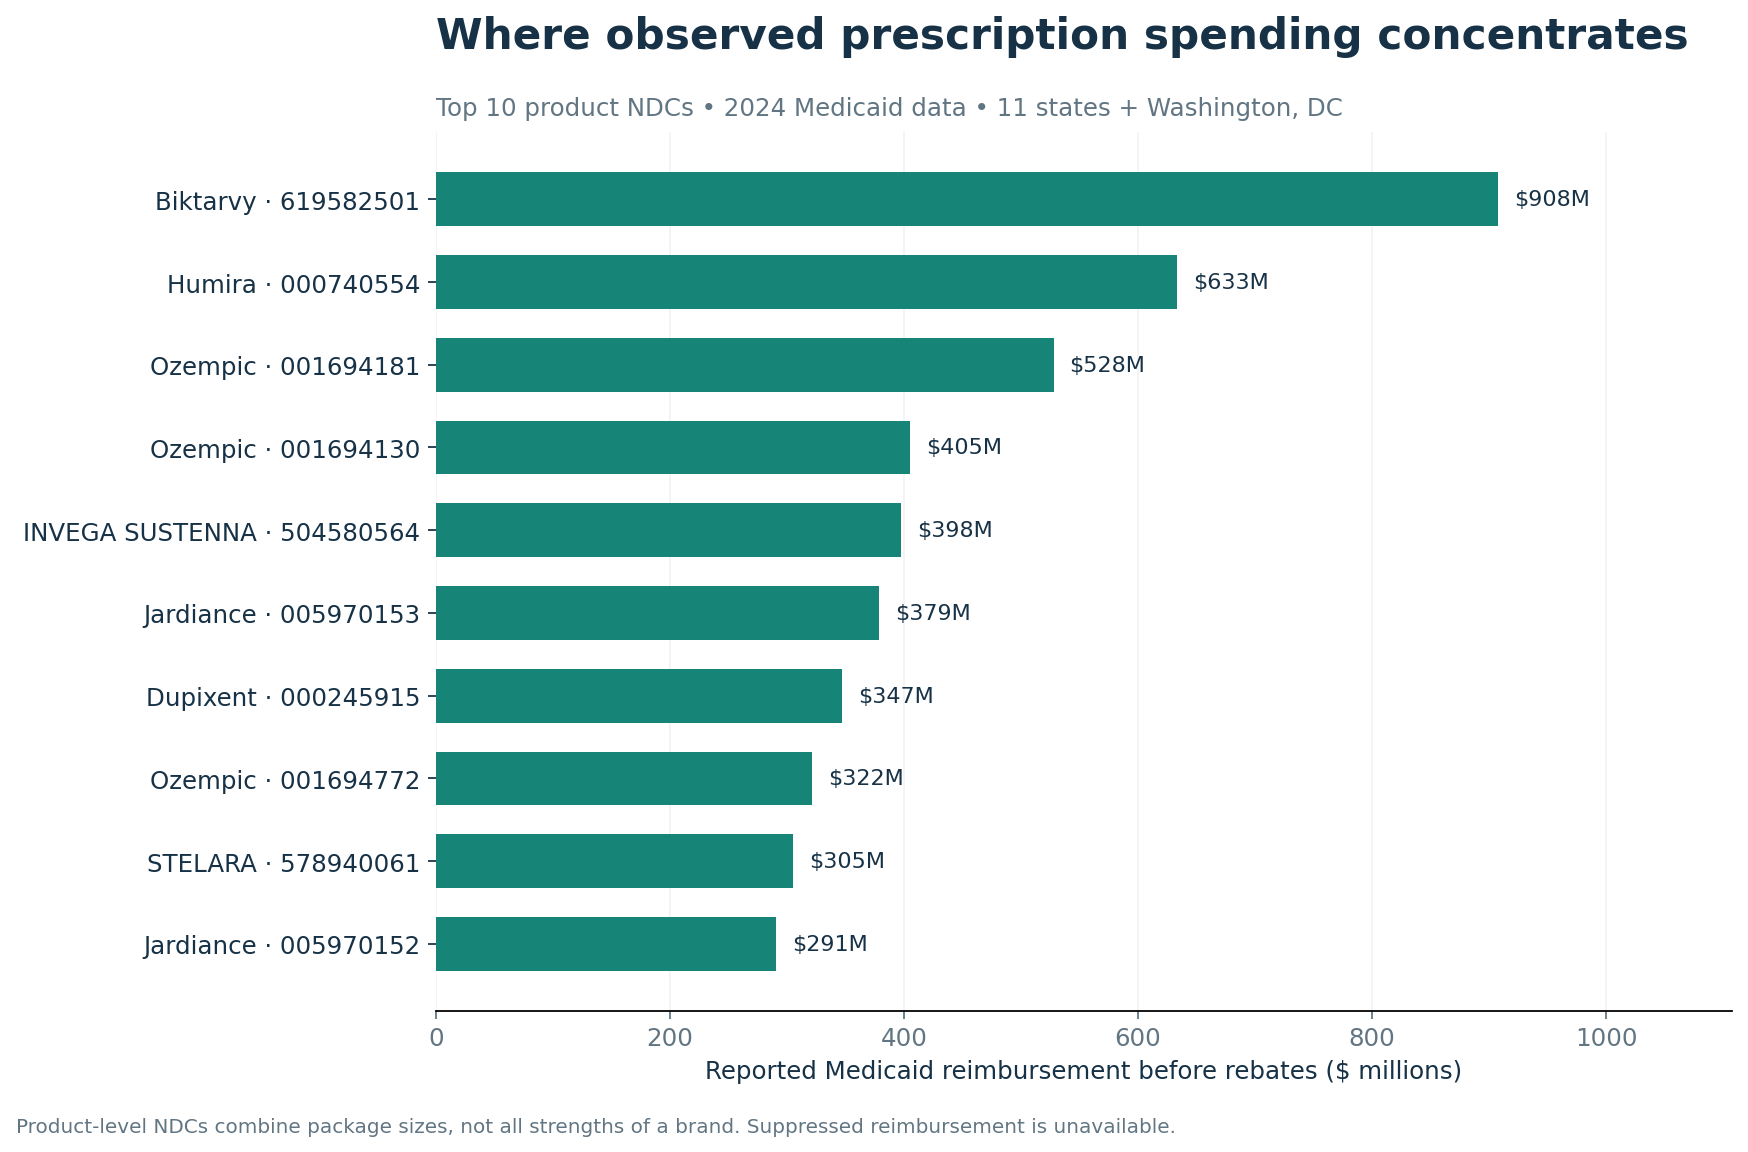

In [6]:
for count in [10, 50, 100]:
    share = products.head(count)["spend_share"].sum()
    print(f"Top {count} product NDCs: {share:.1%} of reported reimbursement")


Top 10 product NDCs: 16.4% of reported reimbursement
Top 50 product NDCs: 37.1% of reported reimbursement
Top 100 product NDCs: 49.5% of reported reimbursement


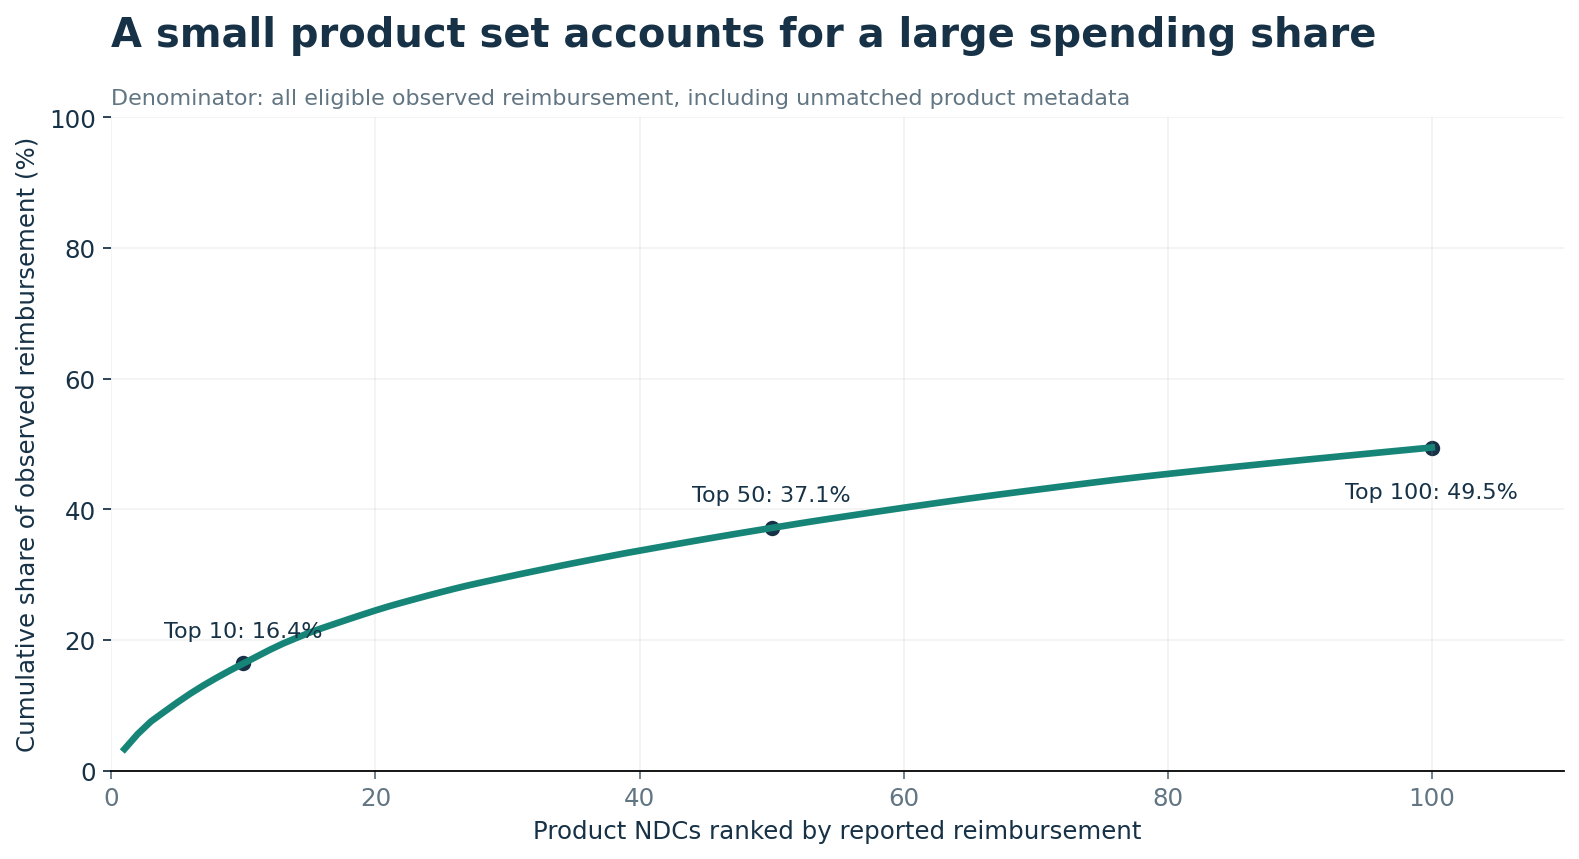

**Observation:** Biktarvy product NDC 619582501 accounts for $907.89M. The top 50 product NDCs account for 37.1% of reimbursement. **Decision:** I would start detailed spending reviews with this concentrated product set rather than treating every product as an equal priority.

## 5. Compare jurisdictions with coverage in view

**Question:** where are the reported dollars concentrated?

I compare jurisdiction totals alongside suppression and record coverage. The SQL query keeps suppressed record counts separate from known reimbursement. These amounts are not adjusted for enrollment or drug mix.

In [7]:
coverage = pd.read_sql_query((ROOT / "sql/jurisdiction_coverage.sql").read_text(), connection)
view = coverage[["state", "source_records", "suppressed_record_share", "reimbursement"]].copy()
view["suppressed_record_share"] = view["suppressed_record_share"].map(lambda x: f"{x:.1%}")
view["reimbursement"] = view["reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
print(view.to_string(index=False))
ca_share = coverage.loc[coverage["state"].eq("CA"), "reimbursement"].sum() / coverage["reimbursement"].sum()
print(f"California share of reported reimbursement: {ca_share:.1%}")


state  source_records suppressed_record_share reimbursement
   CA          160323                   39.4%      $15.554B
   FL          124606                   49.7%       $3.164B
   CT           71030                   46.4%       $1.920B
   AZ           95905                   53.0%       $1.850B
   CO           95583                   54.2%       $1.454B
   GA          127780                   48.9%       $1.241B
   AL           68739                   47.2%       $1.000B
   AR           90130                   54.6%       $0.458B
   DC           74971                   72.5%       $0.247B
   DE           59686                   63.8%       $0.240B
   HI           36236                   57.7%       $0.205B
   AK           43586                   59.0%       $0.205B
California share of reported reimbursement: 56.5%


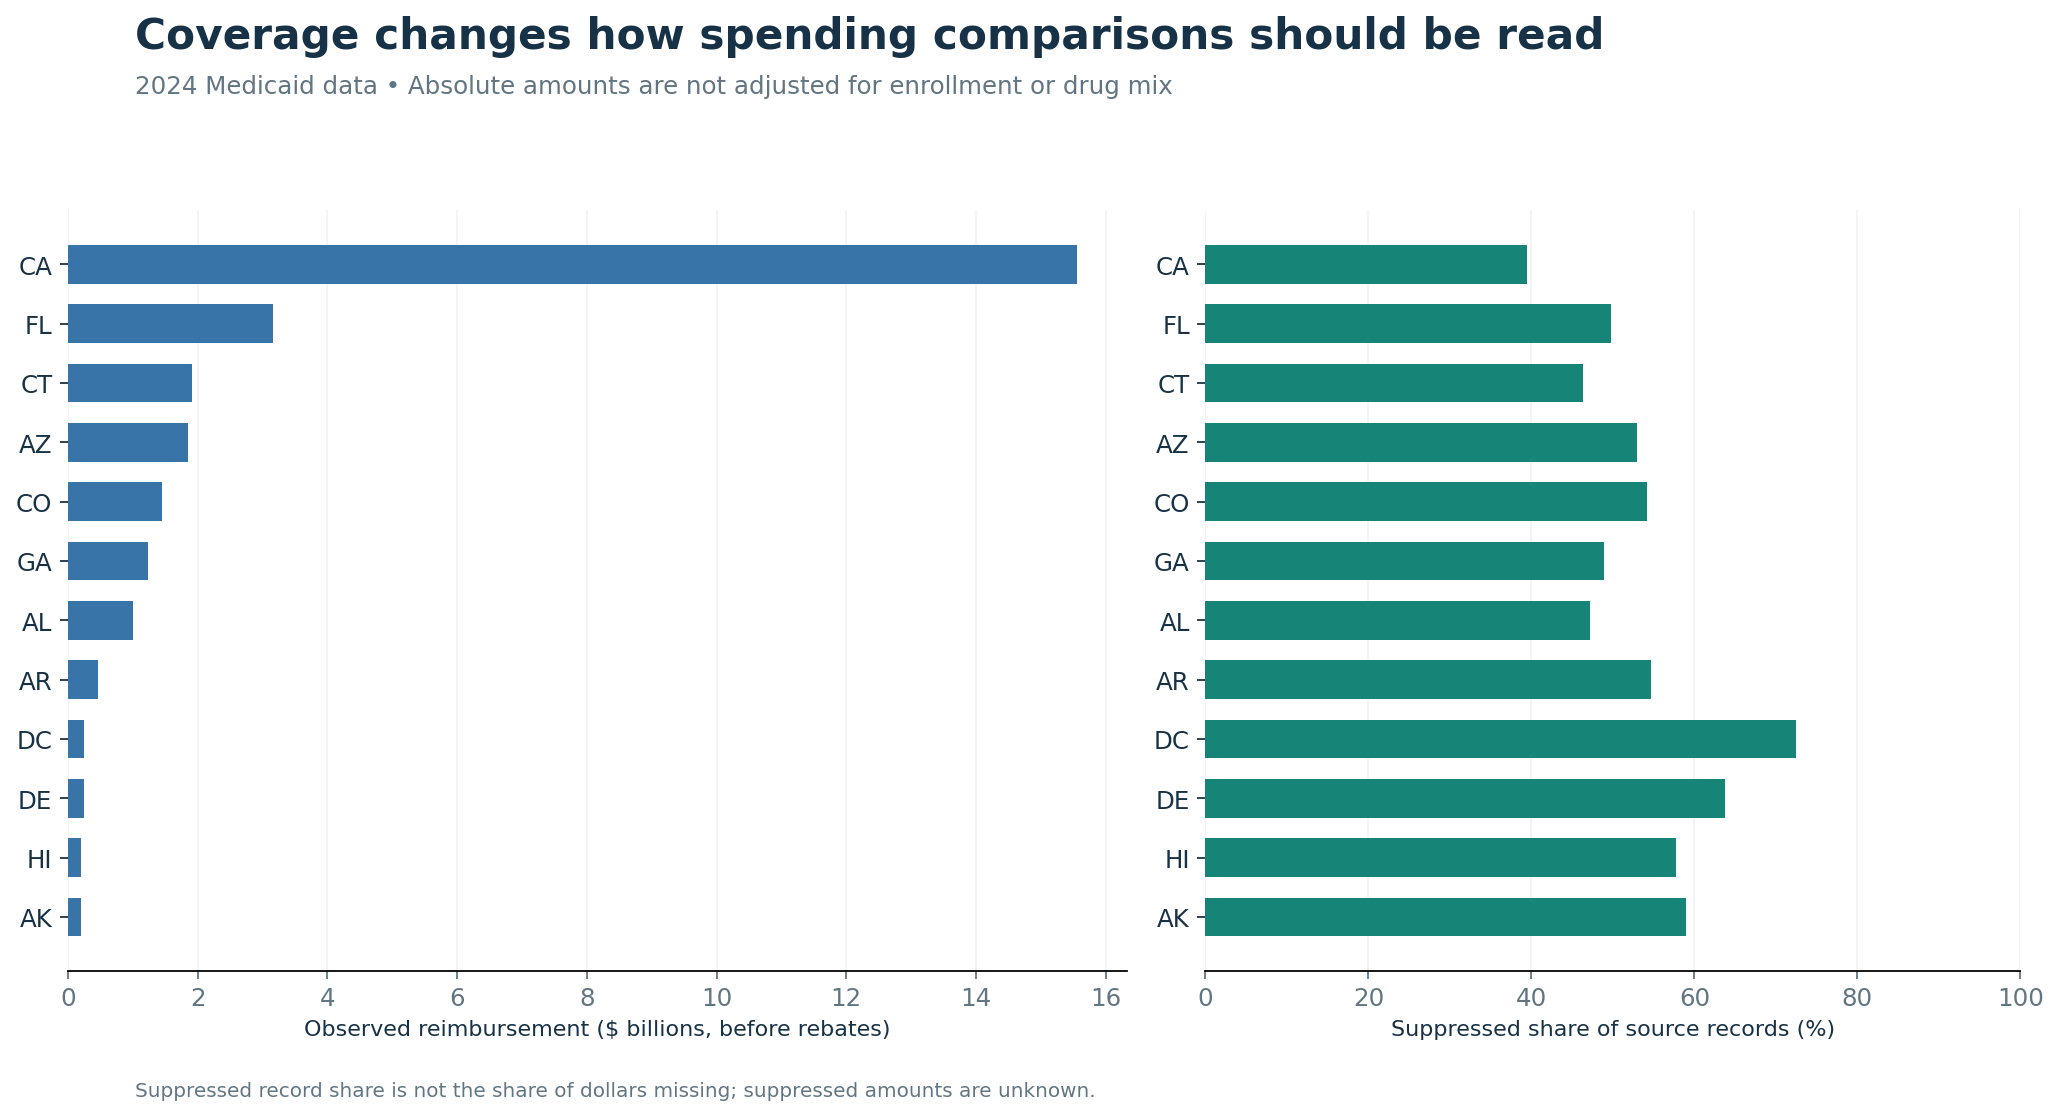

**Observation:** California contributes 56.5% of the dataset's reimbursement. **Interpretation:** this describes concentration in the extract, not relative efficiency. A fair efficiency comparison would require enrollment, patient and drug mix, and confirmed reporting completeness. Suppressed record share is not the share of dollars missing.

## 6. Look at quarters and application categories

I use quarterly totals and `LAG` to describe changes during 2024. I also summarize directory application categories. These comparisons help describe the spending mix; application categories are not a complete brand/generic classification.

In [8]:
quarters = pd.read_sql_query((ROOT / "sql/quarterly_spending.sql").read_text(), connection)
view = quarters[["quarter", "reimbursement", "reimbursement_per_prescription", "quarter_change"]].copy()
view["reimbursement"] = view["reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
view["reimbursement_per_prescription"] = view["reimbursement_per_prescription"].map(lambda x: f"${x:.2f}")
view["quarter_change"] = view["quarter_change"].map(lambda x: "--" if pd.isna(x) else f"{x:+.1%}")
print(view.to_string(index=False))


 quarter reimbursement reimbursement_per_prescription quarter_change
       1       $6.701B                        $145.91             --
       2       $6.365B                        $150.47          -5.0%
       3       $7.630B                        $163.21         +19.9%
       4       $6.845B                        $159.33         -10.3%


In [9]:
applications = pd.read_sql_query((ROOT / "sql/application_spending.sql").read_text(), connection)
view = applications.head(5)[["application_type", "reimbursement", "spend_share"]].copy()
view["reimbursement"] = view["reimbursement"].map(lambda x: f"${x / 1e9:.3f}B")
view["spend_share"] = view["spend_share"].map(lambda x: f"{x:.1%}")
print(view.to_string(index=False))


      application_type reimbursement spend_share
                   NDA      $15.998B       58.1%
                   BLA       $7.931B       28.8%
                  ANDA       $2.845B       10.3%
NDA AUTHORIZED GENERIC       $0.511B        1.9%
             Unmatched       $0.161B        0.6%


**Interpretation:** quarterly changes describe this extract; they do not establish a policy effect. Category totals describe recorded product listings, without implying that every NDA-listed product is a brand or every comparison is substitutable.

## 7. Compare like-for-like recorded formulations

**Question:** where do products with matching recorded descriptors have different reimbursement per unit?

I compare NDA- and ANDA-listed prescription products only when ingredient, strength, strength unit, dosage form, and route match. I also match jurisdiction, quarter, and utilization type, and check whether recorded marketing dates overlap the quarter.

For each side, I calculate **total reimbursement ÷ total units**. I then multiply the unit-price difference by NDA units to obtain a signed gross difference. I retain negative differences and report positive differences separately.

In [10]:
gaps, price_stats = reimbursement_gaps(joined)
print(f"Matched recorded formulations: {price_stats['distinct_paired_formulations']:,}")
print(f"Matched reporting groups: {price_stats['paired_strata']:,}")
print(f"Positive gross reimbursement gap: ${price_stats['illustrative_positive_gross_gap']:,.2f}")
print(f"Signed gross gap, including negative differences: ${price_stats['signed_gross_gap']:,.2f}")
del records, product_records, utilization, directory, joined


Matched recorded formulations: 562
Matched reporting groups: 6,675
Positive gross reimbursement gap: $516,161,761.37
Signed gross gap, including negative differences: $506,733,293.57


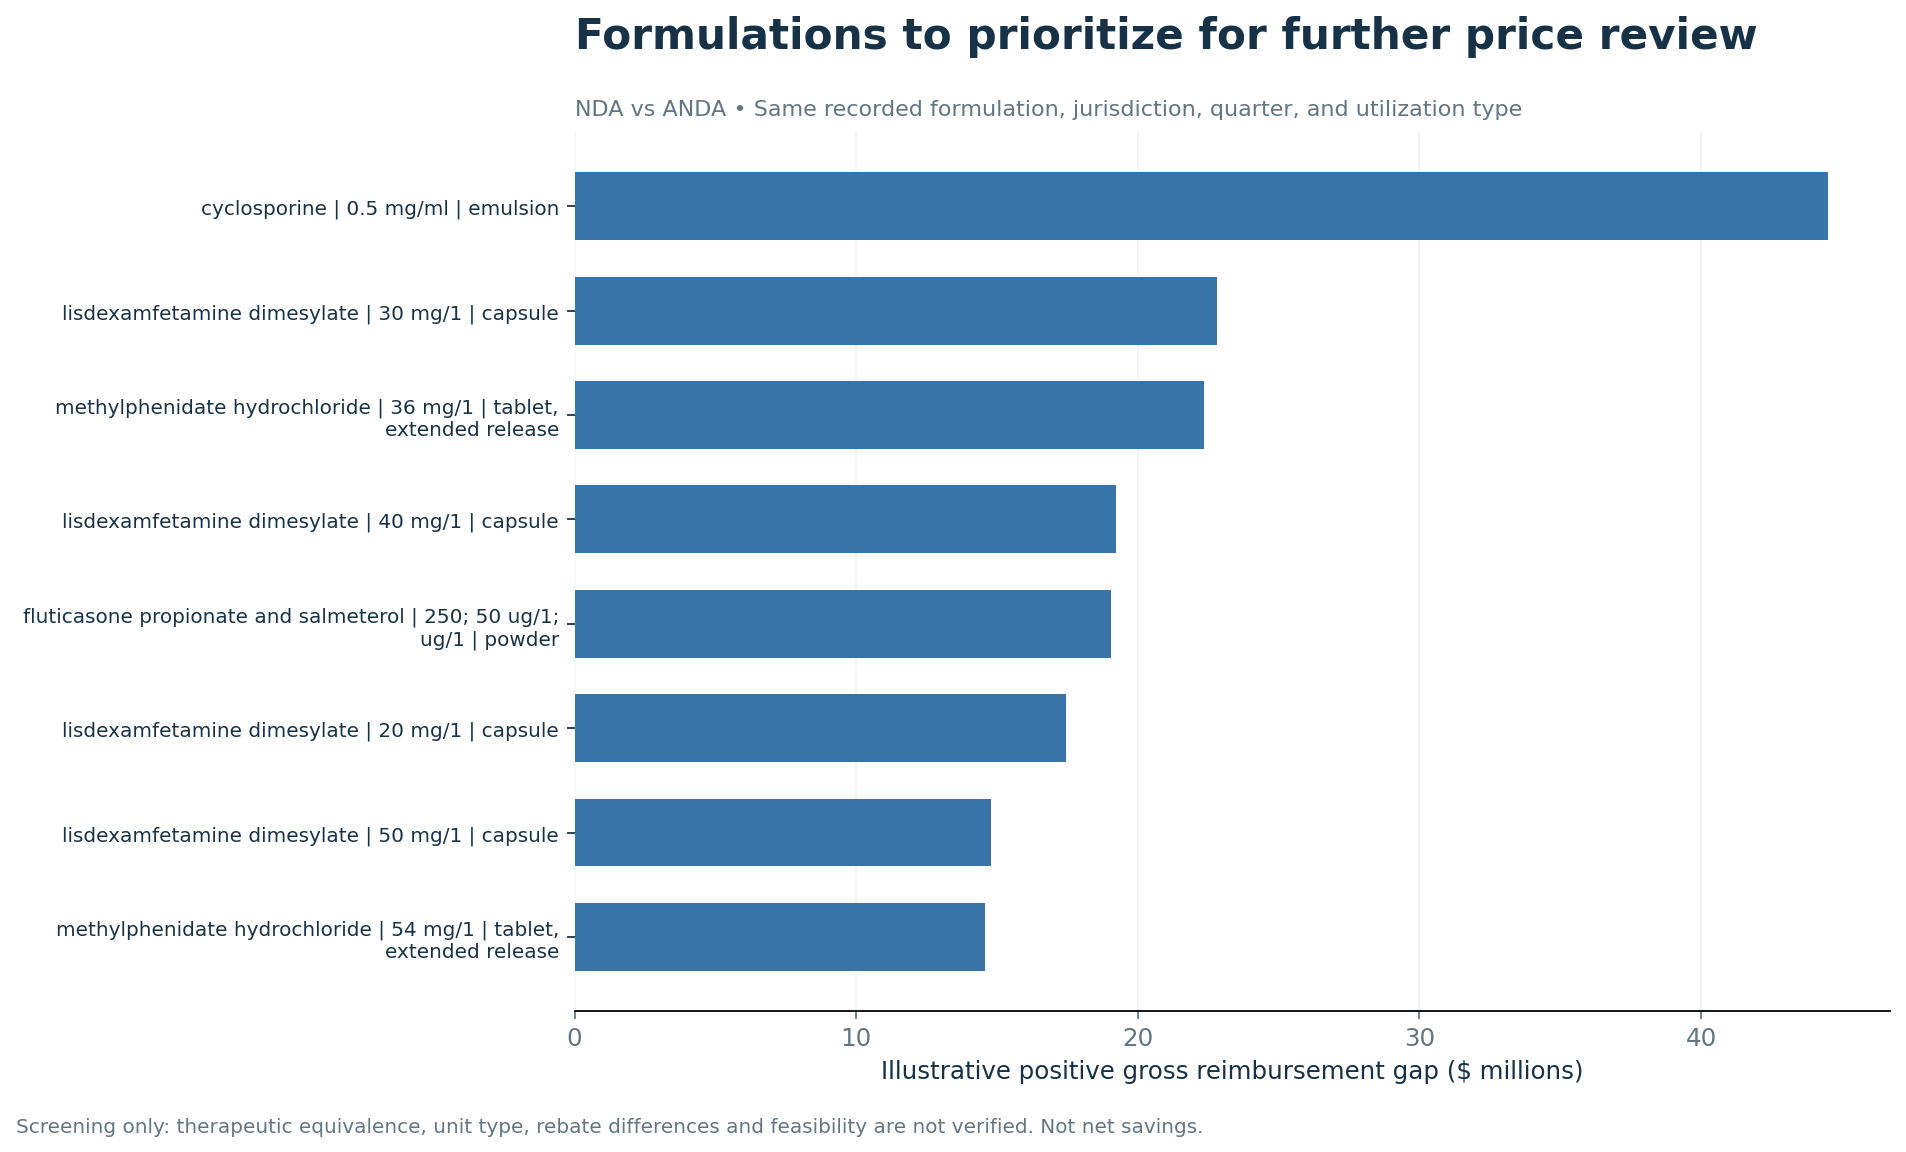

**Result:** 562 recorded formulations appear in 6,675 matched reporting groups. Positive differences sum to $516.16M. **Decision:** I treat these as products to investigate, not as a forecast of savings. The extract lacks verified reimbursement unit types, rebate effects, and therapeutic-equivalence determinations. Identical descriptors do not establish clinical substitutability.

## 8. Check the results and identify the next decision

I check source-file integrity, matching assumptions, spending totals, coverage, and price-comparison bounds. The same checks run in GitHub Actions.

My recommendation is to prioritize the high-dollar product set, then verify complete reporting, unit types, equivalence, availability, and net rebate effects before evaluating an intervention. The spending findings stand on their own; the price comparison supports a narrower investigation.

Details: [methodology](../docs/METHODOLOGY.md), [data guide](../data/README.md), and [SQL queries](../sql/).

In [11]:
verify(ROOT)
connection.close()


PASS: source checksums, spending totals, jurisdiction coverage, and price-comparison bounds
